# OpenCV 入门学习

结合OpenCV官方 Tutorials 和 GPT 学习 OpenCV

## 1. 图像读取与数组基础

<class 'numpy.ndarray'>
(512, 512, 3)
uint8
0 255


[ WARN:0@1387.638] global grfmt_tiff.cpp:122 TIFF_Warning TIFFFetchNormalTag: ASCII value for tag "ImageDescription" does not end in null byte. Forcing it to be null


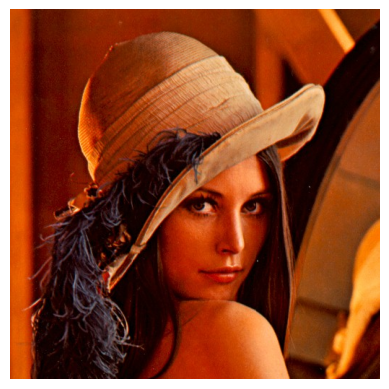

In [32]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

image = cv.imread("testimgs/lenna.tif")

print(type(image))
print(image.shape)
print(image.dtype)
print(image.min(), image.max())

plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

> [!NOTE] 学习目标
> 把图像看成一个 NumPy 数组，理解它的形状、数据类型和通道顺序。

### 练习问题与解答

#### 1. `image` 是什么类型？

`image` 的类型是 `numpy.ndarray`，即 NumPy 的多维数组类型。原回答中的 `np.adarray` 应改为 `np.ndarray`。它可以类比为 C 语言中的数组，但还额外保存了形状和数据类型等信息。

```python
type(image)       # numpy.ndarray
image.shape       # 数组的形状
image.dtype       # 数组中元素的数据类型
```

#### 2. `shape` 表示什么？

对于 512 × 512 的彩色图像，通常有 `image.shape == (512, 512, 3)`。三个数字依次表示高度（行数）、宽度（列数）和通道数。NumPy 的顺序是 `(行, 列, 通道)`，也就是 `(height, width, channels)`。

#### 3. 为什么显示前要进行 BGR 到 RGB 的转换？

OpenCV 读取彩色图像时默认使用 **BGR** 顺序：第 0 个通道是 B，第 1 个是 G，第 2 个是 R。Matplotlib 按 **RGB** 顺序解释图像。如果直接 `plt.imshow(image)`，红色和蓝色会互换，因此显示前通常写：

```python
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
```

> [!IMPORTANT] 读取与显示要分开记
> OpenCV 读取：BGR；Matplotlib 显示：RGB。使用 `cv.imwrite()` 保存时通常不需要转换。

#### 4. `uint8` 是什么？

`uint8` 是 unsigned 8-bit integer，即**无符号 8 位整数**，取值范围是 `0` 到 `255`。这正好适合表示常见图像的像素值：0 表示黑色，255 表示最大亮度。它可以类比 C 语言中的 `unsigned char`。

进行乘法、除法等计算时，常先转换成 `float32`，避免整数运算造成截断或溢出。

#### 5. `image[0, 0]` 表示什么？

它表示第 0 行、第 0 列的像素，也就是左上角像素。Python 和 NumPy 从 0 开始计数。彩色图像中它通常是三个数：`[B_value, G_value, R_value]`，因此不是单独的亮度值。

#### 6. `image[:, :, 0]` 是哪个通道？

它表示所有行、所有列的第 0 个通道。因为 OpenCV 使用 BGR 顺序，所以它是**蓝色通道 B**，不是红色通道。

```python
image[:, :, 0]  # 蓝色通道 B
image[:, :, 1]  # 绿色通道 G
image[:, :, 2]  # 红色通道 R
```

其中 `:` 表示该维度上的全部元素。

### 本节小结

| 表达式 | 含义 |
|---|---|
| `image.shape` | 图像数组的形状 |
| `image.dtype` | 像素数据类型 |
| `image[0, 0]` | 左上角像素的 BGR 值 |
| `image[:, :, 0]` | 蓝色通道 |
| `image[:, :, 1]` | 绿色通道 |
| `image[:, :, 2]` | 红色通道 |
| `cv.cvtColor(image, cv.COLOR_BGR2RGB)` | 将 BGR 转成 RGB 供 Matplotlib 显示 |

## 2. 实验一——图像基本操作

实验一要求掌握读取、显示、保存、翻转、旋转、缩放、灰度化和灰度反转。先学习通道切片、灰度化、翻转和缩放。每做一次操作，都检查输出的 `shape` 和 `dtype`，并判断它改变的是像素值、像素位置，还是数组尺寸。

常用函数：`cv.cvtColor` 改变颜色空间，`cv.flip` 改变像素位置，`cv.resize` 改变图像尺寸，`cv.imwrite` 保存数组。

彩色图： (512, 512, 3) uint8
蓝色通道： (512, 512) uint8
灰度图： (512, 512) uint8
缩小后： (256, 256, 3) uint8


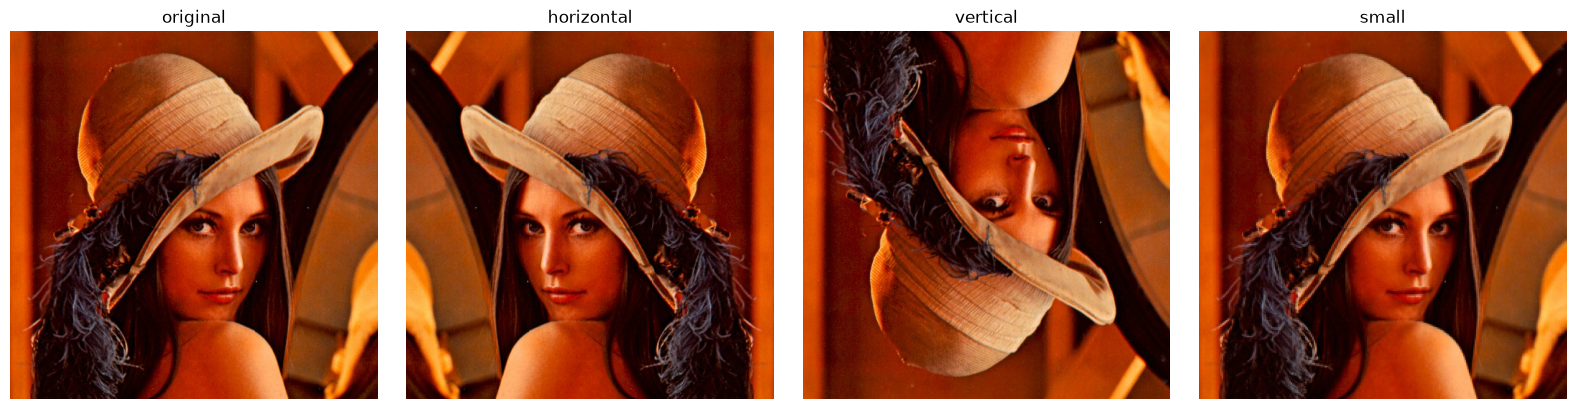

In [33]:
# 通道切片和灰度化
blue = image[:, :, 0]
gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

print("彩色图：", image.shape, image.dtype)
print("蓝色通道：", blue.shape, blue.dtype)
print("灰度图：", gray.shape, gray.dtype)

# 翻转：1 左右翻转，0 上下翻转，-1 两个方向都翻转
flip_horizontal = cv.flip(image, 1)
flip_vertical = cv.flip(image, 0)

# 缩放：宽和高都缩小为原来的 0.5
small = cv.resize(image, None, fx=0.5, fy=0.5, interpolation=cv.INTER_AREA)
print("缩小后：", small.shape, small.dtype)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for axis, item, title in zip(
    axes,
    [image, flip_horizontal, flip_vertical, small],
    ["original", "horizontal", "vertical", "small"]
):
    axis.imshow(cv.cvtColor(item, cv.COLOR_BGR2RGB))
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### 练习问题与解答

#### 1. 灰度图为什么从 `(高度, 宽度, 3)` 变成 `(高度, 宽度)`？

因为彩色图像有 B、G、R 三个通道，而灰度图只保留一个灰度通道。每个位置只需要一个数表示亮度，因此不再需要最后的通道维度。

#### 2. 翻转前后 `shape` 是否改变？

不改变。翻转只改变像素在数组中的位置，不改变图像的高度、宽度和通道数。

#### 3. 缩放后 `shape` 如何变化？

会改变。示例中原图大小为 512 × 512，`fx=0.5`、`fy=0.5` 表示宽度和高度都缩小为原来的一半，因此结果约为 256 × 256。彩色图像的通道数仍然是 3，所以完整形状通常是 `(256, 256, 3)`。

#### 4. 翻转改变的是像素值还是像素位置？

主要改变像素位置，像素本身的 B、G、R 数值通常不变。例如左右翻转会把第 0 列移动到最后一列，把最后一列移动到第 0 列。

#### 5. `cv.INTER_AREA` 起什么作用？

`cv.INTER_AREA` 是 `cv.resize()` 使用的一种插值方法，不是缩放中心。它主要用于图像缩小时，根据目标像素对应的原图区域重新计算像素值，通常能减少缩小过程中的锯齿和混叠，因此适合下采样。

这里的“区域”不是人为指定的中心，而是由原图尺寸、目标图像尺寸以及缩放比例共同决定的。

> [!NOTE] 插值方法的初步理解
> 缩放后新图像中的像素不一定能直接对应原图中的某一个像素，因此需要用附近的原像素估计它的值，这个估计过程就是插值。`INTER_AREA` 更关注一个区域的综合效果；`INTER_NEAREST` 取最近像素；`INTER_LINEAR` 使用邻近像素的线性加权。

### `cv.resize()` 函数

`cv.resize()` 用于改变图像的宽度和高度。官方 Python 形式为：

```python
cv.resize(src, dsize[, dst[, fx[, fy[, interpolation]]]]) -> dst
```

#### 参数含义

| 参数 | 含义 |
|---|---|
| `src` | 输入图像 |
| `dsize` | 输出尺寸，格式为 `(width, height)` |
| `dst` | 输出图像，Python 中通常不需要手动提供 |
| `fx` | 水平方向缩放比例 |
| `fy` | 垂直方向缩放比例 |
| `interpolation` | 插值方法 |

`dsize` 和 `fx、fy` 有两种常用写法。指定 `dsize` 时，尺寸直接由 `(width, height)` 决定：

```python
height, width = image.shape[:2]
resized = cv.resize(image, (width // 2, height // 2),
                    interpolation=cv.INTER_AREA)
```

指定 `fx、fy` 时，把 `dsize` 写成 `None`，让 OpenCV 根据缩放比例计算输出尺寸：

```python
resized = cv.resize(image, None, fx=0.5, fy=0.5,
                    interpolation=cv.INTER_AREA)
```

输出尺寸大致满足：

```text
输出宽度 = 原图宽度 × fx
输出高度 = 原图高度 × fy
```

> [!IMPORTANT] `dsize` 的顺序
> `image.shape` 使用 `(height, width, channels)`，但 `cv.resize()` 的 `dsize` 使用 `(width, height)`。这是两个容易混淆的顺序。

#### 常见插值方法

| 方法 | 含义 | 适用情况 |
|---|---|---|
| `cv.INTER_NEAREST` | 最近邻插值，直接取最近的原图像素 | 速度快、像素风格或标签图；结果可能有锯齿 |
| `cv.INTER_LINEAR` | 双线性插值，使用邻近像素加权计算 | 默认方法，放大时常用，速度和效果较均衡 |
| `cv.INTER_CUBIC` | 双三次插值，参考更大的邻域 | 放大时效果较好，但速度较慢 |
| `cv.INTER_AREA` | 根据像素区域关系进行重采样 | 缩小时通常优先使用，可减少混叠 |
| `cv.INTER_LANCZOS4` | Lanczos 插值，使用 8 × 8 邻域 | 放大质量较高，但计算量更大，可能产生振铃 |

OpenCV 官方的一般建议是：缩小时优先考虑 `INTER_AREA`；放大时可使用 `INTER_LINEAR` 或效果更好但更慢的 `INTER_CUBIC`。默认插值方法是 `INTER_LINEAR`。

#### 插值方法对比练习

```python
methods = {
    "nearest": cv.INTER_NEAREST,
    "linear": cv.INTER_LINEAR,
    "cubic": cv.INTER_CUBIC,
    "area": cv.INTER_AREA,
}

for name, method in methods.items():
    result = cv.resize(image, None, fx=0.5, fy=0.5,
                       interpolation=method)
    print(name, result.shape, result.dtype)
```

观察不同方法生成的图像，重点比较边缘、细节和是否出现锯齿。

## 3. 实验一——旋转、灰度反转与保存

本节学习实验一剩余的三个基本操作：使用 `cv.getRotationMatrix2D()` 和 `cv.warpAffine()` 旋转图像，用像素运算实现灰度反转，以及使用 `cv.imwrite()` 保存结果。

### 图像旋转

`cv.getRotationMatrix2D()` 根据旋转中心、角度和缩放比例生成一个 2 × 3 的仿射变换矩阵；`cv.warpAffine()` 再根据这个矩阵生成旋转后的图像。

```python
height, width = image.shape[:2]
center = (width / 2, height / 2)
matrix = cv.getRotationMatrix2D(center, 45, 1.0)
rotated = cv.warpAffine(image, matrix, (width, height))
```

这里角度为正时表示逆时针旋转，`1.0` 表示不额外缩放。`warpAffine()` 的输出尺寸使用 `(width, height)`，与 `image.shape` 的顺序不同。

> [!NOTE] 旋转中心
> 对于宽度为 `width`、高度为 `height` 的图像，中心点约为 `(width / 2, height / 2)`。坐标顺序是 `(x, y)`，也就是 `(列, 行)`。

### 灰度反转

对于 `uint8` 灰度图像，像素范围是 0 到 255，因此灰度反转可以写成：

```python
gray_inverse = 255 - gray
```

原来较暗的像素会变亮，原来较亮的像素会变暗。例如 0 变成 255，40 变成 215，255 变成 0。这里的运算是逐元素进行的。

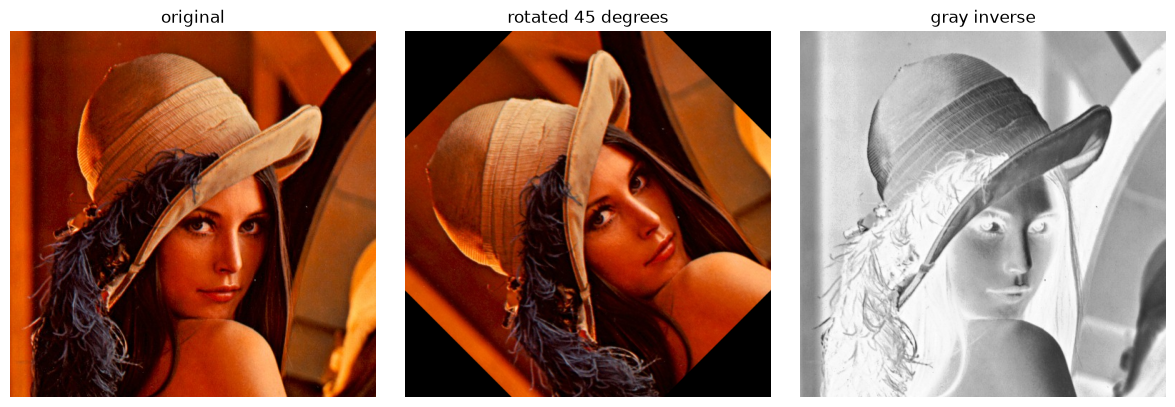

旋转图保存成功： True
反转图保存成功： True


In [34]:
# 旋转 45 度
height, width = image.shape[:2]
center = (width / 2, height / 2)
rotation_matrix = cv.getRotationMatrix2D(center, 45, 1.0)
rotated_45 = cv.warpAffine(image, rotation_matrix, (width, height))

# 灰度反转
gray_inverse = 255 - gray

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
axes[0].set_title("original")
axes[1].imshow(cv.cvtColor(rotated_45, cv.COLOR_BGR2RGB))
axes[1].set_title("rotated 45 degrees")
axes[2].imshow(gray_inverse, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("gray inverse")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

# 保存结果。cv.imwrite() 的返回值表示是否成功写入。
saved = cv.imwrite("learn_rotated_45.jpg", rotated_45)
saved_inverse = cv.imwrite("learn_gray_inverse.png", gray_inverse)
print("旋转图保存成功：", saved)
print("反转图保存成功：", saved_inverse)

### 练习问题与解答

1. 为什么 `center` 的坐标顺序是 `(width / 2, height / 2)`，而不是 `(height / 2, width / 2)`？

   因为 OpenCV 的点坐标使用 `(x, y)`，其中 `x` 表示水平方向的位置，也就是列，因此对应图像宽度；`y` 表示垂直方向的位置，也就是行，因此对应图像高度。

2. `getRotationMatrix2D()` 的第三个参数从 `1.0` 改成 `0.5` 会发生什么？

   它是缩放比例 `scale`。改成 `0.5` 后，图像会围绕旋转中心缩小为原来的约一半，同时进行旋转。输出画布大小仍由 `warpAffine()` 的第三个参数决定。

3. 为什么 `warpAffine()` 的输出尺寸写成 `(width, height)`？

   因为 `warpAffine()` 的输出尺寸参数 `dsize` 遵循 `(宽度, 高度)` 的顺序，而 NumPy 的 `image.shape` 遵循 `(高度, 宽度, 通道)` 的顺序。两者不能混用。

4. 如果把 `gray` 先转换成 `float32`，再执行 `255 - gray`，结果的 `dtype` 会是什么？

   结果会是 `float32`。减法运算通常继承参与运算的浮点数据类型；如果希望保存为普通图像，通常还需要确认数值范围并转换回 `np.uint8`。

5. `cv.imwrite()` 返回 `False` 时，你会检查哪些问题？

   应检查输出路径是否存在且有写入权限、文件名扩展名是否正确、输入数组是否为空、数组类型和形状是否被支持，以及当前 Jupyter 工作目录是否与预期一致。还可以先打印 `os.getcwd()` 和输出文件的绝对路径。

## 4. 实验一——二值图像连通域分析

连通域分析的目标是：在二值图像中找出所有相互连接的前景像素，并给每个区域分配不同的标签。实验要求使用 4 连通区域，并用不同颜色进行可视化。

### 二值图像与前景

通常约定背景像素为 0，前景像素为非 0，例如 255。连通域算法只关心像素是否属于前景，以及前景像素之间是否相邻。

### 4 邻域与 8 邻域

对于位置 `(row, col)` 的像素：

- 4 邻域只包含上、下、左、右四个方向；
- 8 邻域还包含左上、右上、左下、右下四个对角方向。

本实验要求 4 连通，因此本阶段只使用：

```python
offsets_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
```

这里的 `offset` 表示相邻像素相对于当前像素的行、列变化。

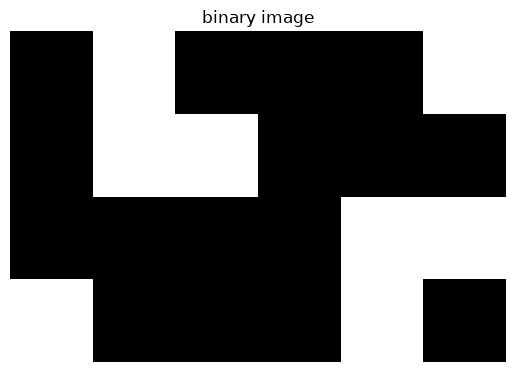

In [35]:
# 构造一个小型二值图像，便于手工观察连通关系
binary = np.array([
    [0, 255, 0,   0,   0,   255],
    [0, 255, 255, 0, 0,   0],
    [0, 0,   0,   0, 255, 255],
    [255, 0, 0,   0, 255, 0],
], dtype=np.uint8)

offsets_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]
offsets_8 = [
    (-1, -1), (-1, 0), (-1, 1),
    (0, -1),           (0, 1),
    (1, -1),  (1, 0),  (1, 1),
]

plt.imshow(binary, cmap="gray", vmin=0, vmax=255)
plt.title("binary image")
plt.axis("off")
plt.show()

### 练习问题与解答

#### 1. 在上面的 `binary` 中，坐标 `(0, 1)` 的 4 邻域有哪些合法位置？

合法位置是 `(1, 1)`、`(0, 0)` 和 `(0, 2)`。上方位置 `(-1, 1)` 越界，因此不合法。这里的问题问的是合法坐标，不要求这些位置一定是前景像素。

#### 2. 为什么访问 `(0, 0)` 的上方像素时会越界？算法应该如何处理？

`(0, 0)` 的上方位置是 `(-1, 0)`，行坐标为负，因此不在图像范围内。算法应该先检查坐标是否满足 `0 <= row < rows` 且 `0 <= col < cols`，越界时直接跳过。相比于把越界位置假设为背景，显式跳过更安全、更清晰。

#### 3. 图中 `(0, 1)`、`(1, 1)` 和 `(1, 2)` 是否属于同一个 4 连通区域？为什么？

是。`(0, 1)` 与 `(1, 1)` 上下相邻，`(1, 1)` 与 `(1, 2)` 左右相邻，因此三个前景像素可以通过 4 邻域路径连通。

#### 4. `(2, 4)` 和 `(3, 0)` 在 4 邻域下是否连通？如果改成 8 邻域，结论会改变吗？

不连通。两者之间没有由相邻前景像素构成的路径；即使允许对角线连接，图中也没有足够的前景像素把这两个区域连接起来，因此改成 8 邻域后仍不连通。

#### 5. 如果已经访问过一个前景像素，为什么后续扫描时不能再次从它开始搜索？

因为同一个连通区域可能被重复搜索，导致重复入队、重复标记，增加时间开销；在某些错误实现中还可能造成无限循环。使用 `visited` 数组可以保证每个像素最多被处理一次。

## 5. 实验一——BFS 种子填充法

种子填充法的核心思想是：找到一个还没有访问过的前景像素，把它作为种子，然后不断寻找与它相连的前景像素，直到这个区域全部访问完。之后继续扫描图像，寻找下一个没有访问过的前景像素。

### 算法步骤

1. 从左到右、从上到下扫描每个像素；
2. 如果当前像素是背景，跳过；
3. 如果当前前景像素已经访问过，跳过；
4. 如果是新的前景区域，标签编号加 1，并把它放入队列；
5. 从队列取出一个像素，检查它的 4 邻域；
6. 将合法、未访问、属于前景的邻居加入队列；
7. 队列为空时，一个连通区域搜索结束。

`visited` 用布尔数组记录像素是否访问过，`labels` 用整数数组记录每个前景像素属于哪个区域。队列可以使用 `collections.deque`，因为从队首取出元素的效率比 Python 列表更合适。

连通区域数量： 4
[[0 1 0 0 0 2]
 [0 1 1 0 0 0]
 [0 0 0 0 3 3]
 [4 0 0 0 3 0]]


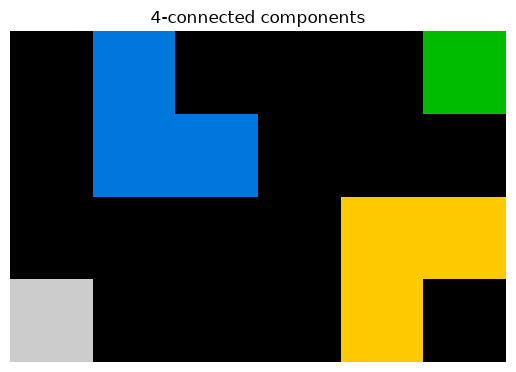

In [36]:
from collections import deque

def label_components(binary):
    foreground = binary > 0
    visited = np.zeros(foreground.shape, dtype=bool)
    labels = np.zeros(foreground.shape, dtype=np.int32)
    offsets = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    component_count = 0

    rows, cols = binary.shape
    for row in range(rows):
        for col in range(cols):
            if not foreground[row, col] or visited[row, col]:
                continue

            component_count += 1
            queue = deque([(row, col)])
            visited[row, col] = True
            labels[row, col] = component_count

            while queue:
                current_row, current_col = queue.popleft()
                for row_offset, col_offset in offsets:
                    neighbor_row = current_row + row_offset
                    neighbor_col = current_col + col_offset
                    inside = (0 <= neighbor_row < rows and
                              0 <= neighbor_col < cols)
                    if not inside:
                        continue
                    if foreground[neighbor_row, neighbor_col] and not visited[neighbor_row, neighbor_col]:
                        visited[neighbor_row, neighbor_col] = True
                        labels[neighbor_row, neighbor_col] = component_count
                        queue.append((neighbor_row, neighbor_col))

    return labels, component_count

labels, count = label_components(binary)
print("连通区域数量：", count)
print(labels)

plt.imshow(labels, cmap="nipy_spectral")
plt.title("4-connected components")
plt.axis("off")
plt.show()

## 6. 实验一——两遍扫描法与并查集

BFS 会从每个新种子出发，把一个连通区域一次搜索完成。两遍扫描法采用另一种思路：先逐行扫描图像并分配临时标签，再处理扫描过程中发现的等价标签，最后重新扫描并统一标签。

### 第一遍扫描

对于当前前景像素，只检查已经扫描过的邻居。在从左到右、从上到下扫描时，4 邻域中只需要检查上方和左方：

```python
previous_offsets = [(-1, 0), (0, -1)]
```

- 如果上方和左方都没有前景像素，分配一个新标签；
- 如果只有一个邻居有标签，使用该邻居的标签；
- 如果两个邻居都有标签但标签不同，暂时使用较小标签，并记录两个标签等价。

两个不同标签可能实际上属于同一个区域，这就是“等价标签”问题。

### 并查集

并查集用于维护标签之间的等价关系。它支持两个核心操作：

- `find(x)`：查找标签 `x` 所属集合的代表；
- `union(x, y)`：把两个集合合并。

第二遍扫描时，对每个临时标签执行 `find()`，把它替换成集合代表，这样同一连通区域就拥有统一标签。

In [37]:
class UnionFind:
    def __init__(self):
        self.parent = {}

    def make_set(self, label):
        self.parent[label] = label

    def find(self, label):
        while self.parent[label] != label:
            self.parent[label] = self.parent[self.parent[label]]
            label = self.parent[label]
        return label

    def union(self, left, right):
        left_root = self.find(left)
        right_root = self.find(right)
        if left_root != right_root:
            self.parent[right_root] = left_root

def two_pass_labels(binary):
    foreground = binary > 0
    labels = np.zeros(binary.shape, dtype=np.int32)
    union_find = UnionFind()
    next_label = 1
    rows, cols = binary.shape

    for row in range(rows):
        for col in range(cols):
            if not foreground[row, col]:
                continue
            neighbor_labels = []
            if row > 0 and labels[row - 1, col] > 0:
                neighbor_labels.append(labels[row - 1, col])
            if col > 0 and labels[row, col - 1] > 0:
                neighbor_labels.append(labels[row, col - 1])

            if not neighbor_labels:
                labels[row, col] = next_label
                union_find.make_set(next_label)
                next_label += 1
            else:
                labels[row, col] = min(neighbor_labels)
                for label in neighbor_labels:
                    union_find.union(labels[row, col], label)

    for row in range(rows):
        for col in range(cols):
            if labels[row, col] > 0:
                labels[row, col] = union_find.find(labels[row, col])
    return labels

two_pass_result = two_pass_labels(binary)
print(two_pass_result)

[[0 1 0 0 0 2]
 [0 1 1 0 0 0]
 [0 0 0 0 3 3]
 [4 0 0 0 3 0]]


## 7. 实验一——连通域可视化与复杂度分析

标签数组中的整数只表示区域编号，不适合直接作为彩色图像显示。因此需要为每个标签分配一个颜色，背景保持黑色。

### 两种算法的比较

BFS 种子填充法和两遍扫描法的处理顺序不同，因此它们生成的标签编号不一定完全相同，但应该满足：

- 前景区域数量相同；
- 同一个区域内的像素标签相同；
- 不同连通区域不会被错误合并。

对于大小为 `H × W` 的图像，两种算法都需要扫描图像中的像素，因此时间复杂度为 `O(HW)`。BFS 需要保存队列和访问数组；两遍扫描法需要保存标签数组和并查集结构，因此空间复杂度也都是 `O(HW)`，两遍扫描法还额外需要保存等价标签关系。

BFS 区域数量： 4
两遍扫描区域数量： 4


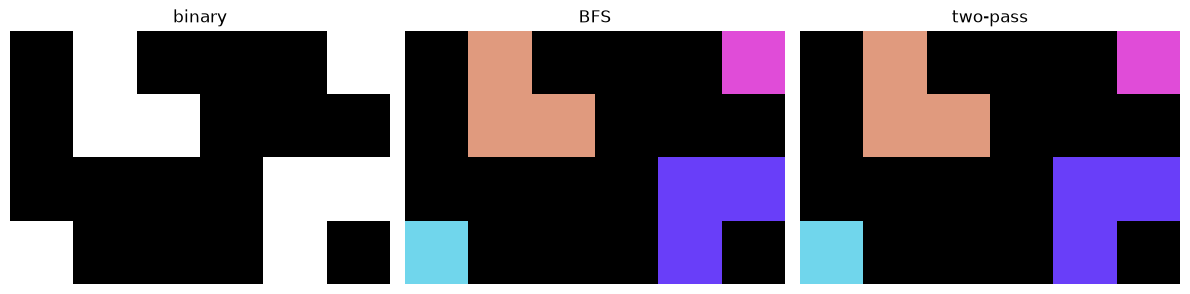

In [38]:
def colorize_labels(labels):
    color_image = np.zeros((*labels.shape, 3), dtype=np.uint8)
    label_values = np.unique(labels)
    rng = np.random.default_rng(0)

    for label in label_values:
        if label == 0:
            continue
        color = rng.integers(50, 256, size=3, dtype=np.uint8)
        color_image[labels == label] = color
    return color_image

bfs_color = colorize_labels(labels)
two_pass_color = colorize_labels(two_pass_result)

print("BFS 区域数量：", len(np.unique(labels)) - 1)
print("两遍扫描区域数量：", len(np.unique(two_pass_result)) - 1)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(binary, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("binary")
axes[1].imshow(cv.cvtColor(bfs_color, cv.COLOR_BGR2RGB))
axes[1].set_title("BFS")
axes[2].imshow(cv.cvtColor(two_pass_color, cv.COLOR_BGR2RGB))
axes[2].set_title("two-pass")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

### 实验一小结

实验一已经覆盖了图像读取、显示、保存、翻转、旋转、缩放、灰度化、灰度反转、二值图像和连通域分析。下一部分将进入实验二的灰度变换，从最简单的固定阈值二值化开始。

## 8. 实验二——固定阈值二值化

实验二的第一部分要求使用固定阈值对 `cameraman.tif` 进行二值化，阈值分别为 50、100 和 200。

### 灰度映射

固定阈值变换逐像素判断灰度值 `r` 与阈值 `T` 的关系：

```text
r > T  ->  255
r <= T ->  0
```

这是一种灰度映射。输出图像只包含 0 和 255，因此称为二值图像。实验要求手动实现，因此本节不使用 `cv.threshold()`。

### 布尔掩膜

表达式 `gray > threshold` 会逐像素比较，生成一个布尔数组。这个布尔数组称为掩膜，`True` 表示满足条件的像素，`False` 表示不满足条件的像素。然后使用 `np.where()` 将布尔值映射为 255 和 0。

T = 50 shape = (256, 256) dtype = uint8 unique = [  0 255]
T = 100 shape = (256, 256) dtype = uint8 unique = [  0 255]
T = 200 shape = (256, 256) dtype = uint8 unique = [  0 255]


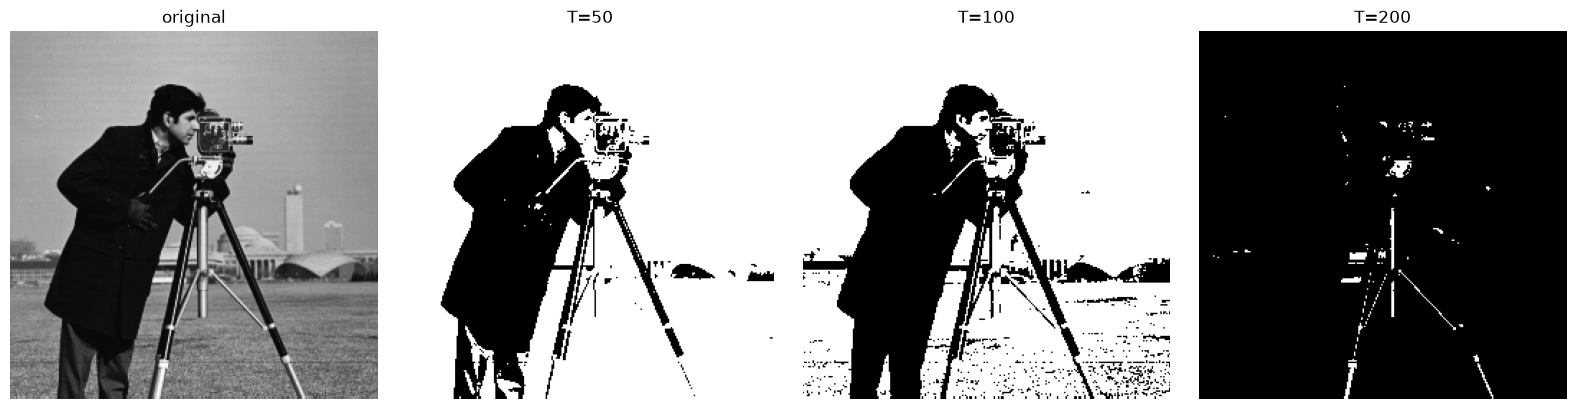

In [39]:
cameraman_gray = cv.imread("testimgs/cameraman.tif", cv.IMREAD_GRAYSCALE)
if cameraman_gray is None:
    raise FileNotFoundError("无法读取 testimgs/cameraman.tif")

thresholds = [50, 100, 200]
binary_images = []

for threshold in thresholds:
    mask = cameraman_gray > threshold # 布尔掩膜
    binary = np.where(mask, 255, 0).astype(np.uint8)
    binary_images.append(binary)
    print("T =", threshold, "shape =", binary.shape,
          "dtype =", binary.dtype,
          "unique =", np.unique(binary))

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(cameraman_gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("original")
for axis, binary, threshold in zip(axes[1:], binary_images, thresholds):
    axis.imshow(binary, cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"T={threshold}")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

### 练习问题与解答

#### 1. `gray > threshold` 的结果为什么不是普通的灰度图？

因为比较运算的结果是布尔数组，每个位置只有 `True` 或 `False`，表示该像素是否超过阈值。它还不是最终的 0/255 二值图像。

#### 2. `np.where(mask, 255, 0)` 做了什么？

它逐元素检查 `mask`：位置为 `True` 时输出 255，位置为 `False` 时输出 0。

#### 3. 为什么最后要使用 `.astype(np.uint8)`？

为了把结果转换成常见的图像数据类型 `uint8`。这样每个像素使用 8 位无符号整数表示，取值范围是 0 到 255。

#### 4. 阈值从 50 增大到 200 时，白色区域通常会怎样变化？

白色区域通常会减少，因为只有灰度值大于更高阈值的像素才能变成 255。阈值越高，保留下来的亮区域越少。

## 9. 实验二——线性对比度变换

实验二的第二部分要求使用 `barbara.tif` 完成图像对比度降低和提高。线性灰度变换的公式为：

```text
s = αr + β
```

其中 `r` 是输入像素值，`s` 是输出像素值，`α` 控制对比度，`β` 控制亮度。

- `α < 1`：灰度差异被压缩，对比度降低；
- `α > 1`：灰度差异被放大，对比度提高；
- `β > 0`：整体变亮；
- `β < 0`：整体变暗。

本实验令 `β = 0`，只改变对比度。由于 `α` 可能是小数，计算前先转换为 `float32`；计算后使用 `np.clip()` 将结果限制在 0 到 255，再转换回 `uint8`。

原图范围： 4 247
降低对比度后： 2 123
提高对比度后： 6 255


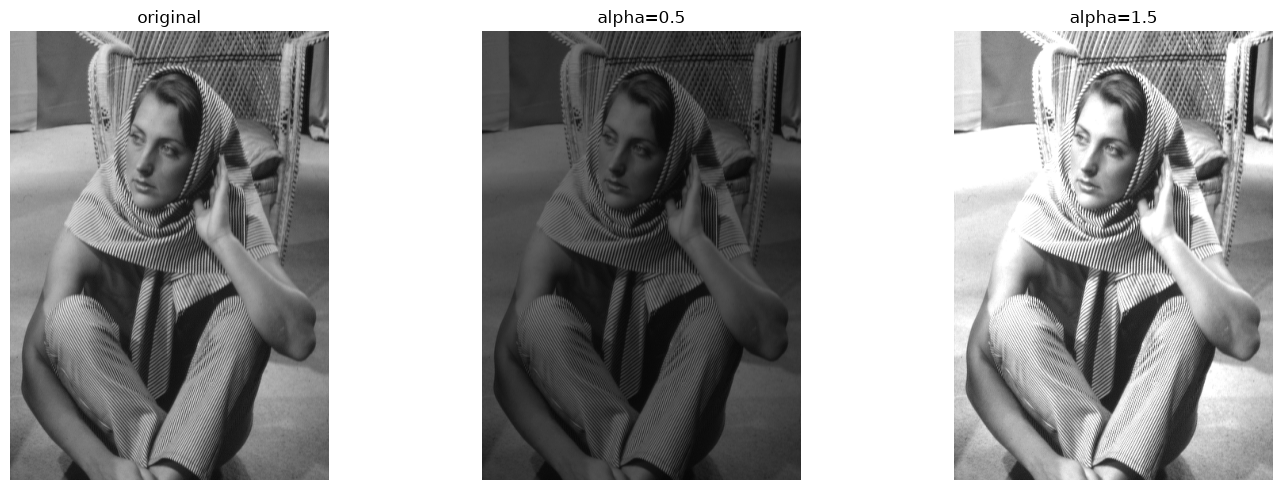

In [40]:
barbara_gray = cv.imread("testimgs/barbara.tif", cv.IMREAD_GRAYSCALE)
if barbara_gray is None:
    raise FileNotFoundError("无法读取 testimgs/barbara.tif")

def linear_transform(gray, alpha, beta=0):
    transformed = gray.astype(np.float32) * alpha + beta
    return np.clip(transformed, 0, 255).astype(np.uint8)

alpha_low = 0.5
alpha_high = 1.5
barbara_low = linear_transform(barbara_gray, alpha_low)
barbara_high = linear_transform(barbara_gray, alpha_high)

print("原图范围：", barbara_gray.min(), barbara_gray.max())
print("降低对比度后：", barbara_low.min(), barbara_low.max())
print("提高对比度后：", barbara_high.min(), barbara_high.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, item, title in zip(
    axes,
    [barbara_gray, barbara_low, barbara_high],
    ["original", "alpha=0.5", "alpha=1.5"]
):
    axis.imshow(item, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

### 练习问题与解答

#### 1. 为什么计算前要转换成 `float32`？

因为 `α` 可能是小数，浮点类型可以保留中间计算结果；同时可以避免直接使用 `uint8` 运算时出现整数截断或溢出。

#### 2. 为什么计算后要使用 `np.clip()`？

当 `α > 1` 或 `β > 0` 时，部分结果可能大于 255；当 `β < 0` 时，部分结果可能小于 0。图像像素必须限制在 `[0, 255]`，因此需要先裁剪再转换为 `uint8`。

#### 3. 为什么不能直接把超过 255 的浮点数转换成 `uint8`？

直接转换可能导致整数回绕，使超过 255 的值变成较小的数，图像中会出现异常的暗点。正确顺序是先 `np.clip()`，再 `.astype(np.uint8)`。

#### 4. `α = 0.5` 和 `α = 1.5` 时图像分别有什么变化？

`α = 0.5` 使灰度值向中间压缩，对比度降低；`α = 1.5` 拉大灰度差异，对比度提高，但高亮区域可能超过 255 并被裁剪成白色。

### `np.clip()` 函数

`np.clip()` 用于把 NumPy 数组中的每个元素限制在给定的最小值和最大值之间。基本形式为：

```python
np.clip(array, min_value, max_value)
```

它的作用是**裁剪**，不是按比例重新映射：

- 小于 `min_value` 的元素变成 `min_value`；
- 位于范围内的元素保持不变；
- 大于 `max_value` 的元素变成 `max_value`。

例如：

```python
values = np.array([-20, 0, 100, 260])
result = np.clip(values, 0, 255)
print(result)
# [  0   0 100 255]
```

在对比度变换中，`np.clip(transformed, 0, 255)` 的作用是保证所有像素值都符合 `uint8` 图像的范围，然后再执行 `.astype(np.uint8)`。它不会把整个数组的最小值和最大值拉伸到 0 和 255；这种按比例拉伸是另一种归一化操作。

## 10. 实验二——直方图均衡化

直方图表示图像中各灰度级出现的次数。直方图均衡化利用累积分布函数（CDF）构造灰度映射，使原本集中在某个范围内的灰度尽量扩展到更大的范围，从而增强对比度。

### 直方图与 CDF

对于 8 位灰度图像，灰度级为 0 到 255。直方图 `hist[k]` 表示灰度值 `k` 出现的次数；CDF 是直方图的累加结果：

```python
hist = np.bincount(gray.ravel(), minlength=256)
cdf = np.cumsum(hist)
```

根据实验指导书中的公式，可以构造查找表：

```python
lut[k] = round(255 * cdf[k] / gray.size)
```

`lut` 有 256 个元素，表示每个旧灰度值应该映射成什么新灰度值。最后使用 `lut[gray]` 一次性完成整幅图像的映射。

原图： (512, 512, 3) uint8
均衡化后： (512, 512, 3) uint8


[ WARN:0@1388.376] global grfmt_tiff.cpp:122 TIFF_Warning TIFFFetchNormalTag: ASCII value for tag "ImageDescription" does not end in null byte. Forcing it to be null


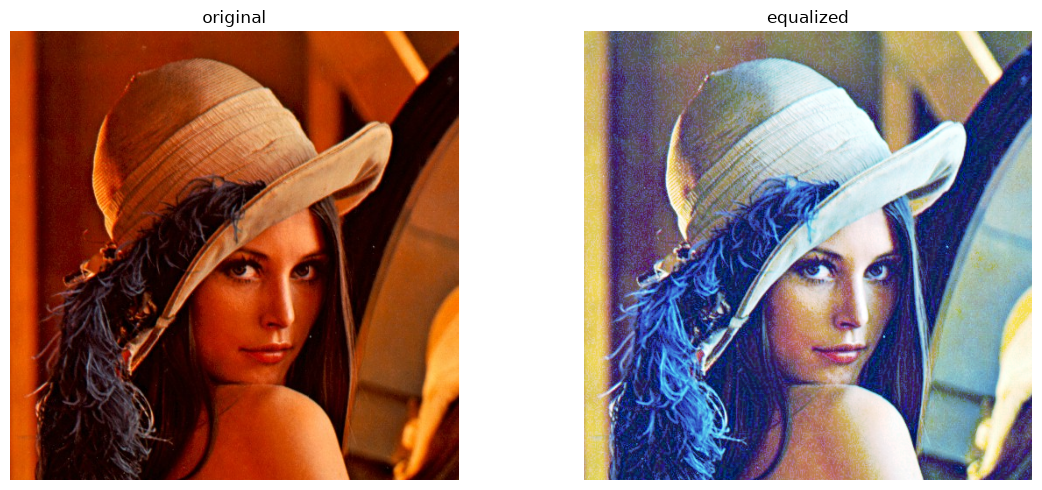

In [41]:
def histogram_equalize(gray):
    if gray.dtype != np.uint8 or gray.ndim != 2:
        raise ValueError("输入必须是二维 uint8 灰度图")

    hist = np.bincount(gray.ravel(), minlength=256)
    cdf = np.cumsum(hist)
    lut = np.round(255 * cdf / gray.size).astype(np.uint8)
    return lut[gray]

lenna = cv.imread("testimgs/lenna.tif")
if lenna is None:
    raise FileNotFoundError("无法读取 testimgs/lenna.tif")

blue, green, red = cv.split(lenna)
blue_equalized = histogram_equalize(blue)
green_equalized = histogram_equalize(green)
red_equalized = histogram_equalize(red)
lenna_equalized = cv.merge([blue_equalized, green_equalized, red_equalized])

print("原图：", lenna.shape, lenna.dtype)
print("均衡化后：", lenna_equalized.shape, lenna_equalized.dtype)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv.cvtColor(lenna, cv.COLOR_BGR2RGB))
axes[0].set_title("original")
axes[1].imshow(cv.cvtColor(lenna_equalized, cv.COLOR_BGR2RGB))
axes[1].set_title("equalized")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

### 练习问题与解答

#### 1. `gray.ravel()` 的作用是什么？

它把二维图像数组展平成一维数组，但通常不复制数据。这样可以把所有像素放在一起，方便统计灰度值出现的次数。

#### 2. `np.bincount()` 为什么可以得到直方图？

`np.bincount()` 会统计每个非负整数出现的次数。灰度值本身就是 0 到 255 的整数，因此返回数组的下标可以直接对应灰度级。

#### 3. `np.cumsum(hist)` 得到的是什么？

它得到累积直方图，即每个灰度级及其之前所有灰度级的像素数量之和，也就是离散形式的 CDF。

#### 4. 为什么可以使用 `lut[gray]` 映射整幅图？

因为 `lut` 的下标是旧灰度值，`gray` 中的每个元素都可以作为下标查表。NumPy 会对整个数组逐元素执行查表，因此不需要手写双重像素循环。

#### 5. 为什么彩色图像要分别处理三个通道？

彩色图像的每个通道都有自己的灰度分布。分别均衡 B、G、R 通道可以按照实验要求增强各通道对比度，但也可能改变三个通道之间的比例，从而改变整体颜色。

### CDF 公式

设一幅灰度图像的灰度级范围为 `0, 1, ..., L-1`，灰度级 `r_k` 出现的像素数量为 `n_k`，图像总像素数为 `N`。

灰度级 `r_k` 出现的概率，也就是归一化直方图为：

$$
p_r(r_k) = \frac{n_k}{N}, \qquad k = 0, 1, \ldots, L-1
$$

累积分布函数（CDF）是从灰度级 0 累加到当前灰度级 `r_k` 的概率：

$$
CDF(r_k) = \sum_{j=0}^{k} p_r(r_j)
= \frac{1}{N} \sum_{j=0}^{k} n_j
$$

按照本实验指导书中的直方图均衡公式，输出灰度值为：

$$
s_k = T(r_k) = (L-1) \, CDF(r_k)
= \frac{L-1}{N} \sum_{j=0}^{k} n_j
$$

对于 8 位图像，`L = 256`，所以：

$$
s_k = \operatorname{round}\left(255 \times CDF(r_k)\right)
= \operatorname{round}\left(255 \times \frac{\sum_{j=0}^{k} n_j}{N}\right)
$$

代码中的对应关系是：

```python
hist = np.bincount(gray.ravel(), minlength=256)
cdf = np.cumsum(hist)
lut = np.round(255 * cdf / gray.size).astype(np.uint8)
```

其中 `hist` 对应 `n_k`，`gray.size` 对应 `N`，`lut[k]` 对应灰度级 `r_k` 的输出值 `s_k`。

## 11. 实验二——图像白平衡

白平衡用于校正光源颜色造成的偏色。例如，暖色光源可能使图像偏黄，冷色光源可能使图像偏蓝。白平衡的本质是分别调整 B、G、R 三个通道的增益。

### 灰度世界法

灰度世界法假设：如果图像包含足够丰富的颜色，整幅图像三个通道的平均值应该接近同一个灰度值 `K`。设三个通道的平均值为 `B_avg、G_avg、R_avg`，则：

$$
K = \frac{B_{avg} + G_{avg} + R_{avg}}{3}
$$

每个通道的增益为：

$$
g_B = \frac{K}{B_{avg}}, \qquad
g_G = \frac{K}{G_{avg}}, \qquad
g_R = \frac{K}{R_{avg}}
$$

然后对每个像素的三个通道分别乘以对应增益。

### 完美反射法

完美反射法假设图像中最亮的一部分像素接近白色。具体步骤是：

1. 计算每个像素的 `B + G + R`；
2. 选择亮度总和最大的前 10% 像素；
3. 求这些像素三个通道的平均值，作为白点参考；
4. 根据白点为各通道计算增益，并调整整幅图像。

该方法依赖图像中确实存在接近白色的区域；如果最亮区域本身是黄色灯光或夕阳，校正结果可能不理想。

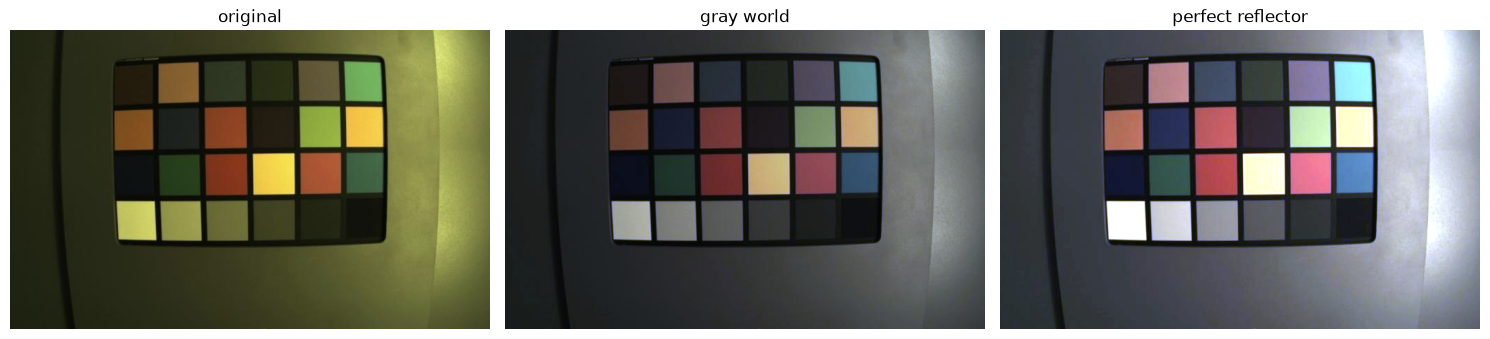

原图各通道均值 BGR： [39.97018913 78.34167998 78.86582765]
灰度世界法均值 BGR： [65.22327016 65.24678673 65.15434424]


In [42]:
def safe_uint8(image_float):
    return np.clip(image_float, 0, 255).astype(np.uint8)

def gray_world_balance(image):
    image_float = image.astype(np.float32)
    channel_average = image_float.reshape(-1, 3).mean(axis=0)
    target = channel_average.mean()
    gain = target / channel_average
    return safe_uint8(image_float * gain)

def perfect_reflector_balance(image, ratio=0.1):
    image_float = image.astype(np.float32)
    brightness = image_float.sum(axis=2)
    threshold = np.percentile(brightness, (1 - ratio) * 100)
    white_pixels = image_float[brightness >= threshold]
    white_point = white_pixels.mean(axis=0)
    gain = 255.0 / white_point
    return safe_uint8(image_float * gain)

image_path = "testimgs/whiteBalance/color.png"
white_balance_input = cv.imread(image_path)
if white_balance_input is None:
    raise FileNotFoundError(f"无法读取 {image_path}")

gray_world_result = gray_world_balance(white_balance_input)
perfect_reflector_result = perfect_reflector_balance(white_balance_input)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for axis, item, title in zip(
    axes,
    [white_balance_input, gray_world_result, perfect_reflector_result],
    ["original", "gray world", "perfect reflector"]
):
    axis.imshow(cv.cvtColor(item, cv.COLOR_BGR2RGB))
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()

print("原图各通道均值 BGR：", white_balance_input.reshape(-1, 3).mean(axis=0))
print("灰度世界法均值 BGR：", gray_world_result.reshape(-1, 3).mean(axis=0))

### 练习问题与解答

#### 1. 为什么白平衡要分别调整三个通道？

因为偏色通常表现为 B、G、R 三个通道的整体比例不平衡。分别使用不同增益，才能对不同通道进行不同程度的补偿。

#### 2. 灰度世界法中的 `gain` 是什么？

`gain` 是每个通道的增益数组。某个通道平均值偏低时，其增益大于 1；平均值偏高时，其增益小于 1。

#### 3. `image_float * gain` 为什么可以直接计算？

图像形状是 `(H, W, 3)`，`gain` 形状是 `(3,)`。NumPy 会沿最后一个维度进行广播，使三个增益分别作用于 B、G、R 三个通道。

#### 4. 为什么白平衡计算时要使用浮点数？

通道增益通常是小数。如果直接使用 `uint8` 计算，可能发生整数截断或溢出；使用 `float32` 可以保留中间结果，最后再裁剪并转换成 `uint8`。

#### 5. 两种白平衡方法分别适合什么情况？

灰度世界法适合颜色丰富、整体平均接近灰色的图像；完美反射法适合图像中确实存在白色或近似白色高光区域的图像。两种方法都可能因为自身假设不成立而产生偏色或过度校正。

## 12. 实验三——傅里叶变换与频域表示

实验三的核心是把图像从空间域转换到频率域，在频率域中观察和修改图像，再转换回空间域。

### 空间域与频率域

空间域直接处理像素值，例如灰度变换、阈值化和空域滤波。频率域不直接观察单个像素，而是分析图像中不同空间频率成分的强弱：

- 低频通常对应缓慢变化的区域、整体亮度和较平滑的结构；
- 高频通常对应快速变化的区域，例如边缘、纹理和噪声。

二维离散傅里叶变换可以写成：

$$
F(u,v) = \sum_{x=0}^{M-1} \sum_{y=0}^{N-1} f(x,y)
e^{-j2\pi(ux/M + vy/N)}
$$

其中 `f(x,y)` 是空间域图像，`F(u,v)` 是频域复数结果。频谱显示时通常使用幅度：

$$
|F(u,v)| = \sqrt{\operatorname{Re}(F)^2 + \operatorname{Im}(F)^2}
$$

由于幅度范围可能很大，显示频谱时通常使用 `log(1 + |F|)`。

空间域： (256, 256) uint8
频域： (256, 256) complex128


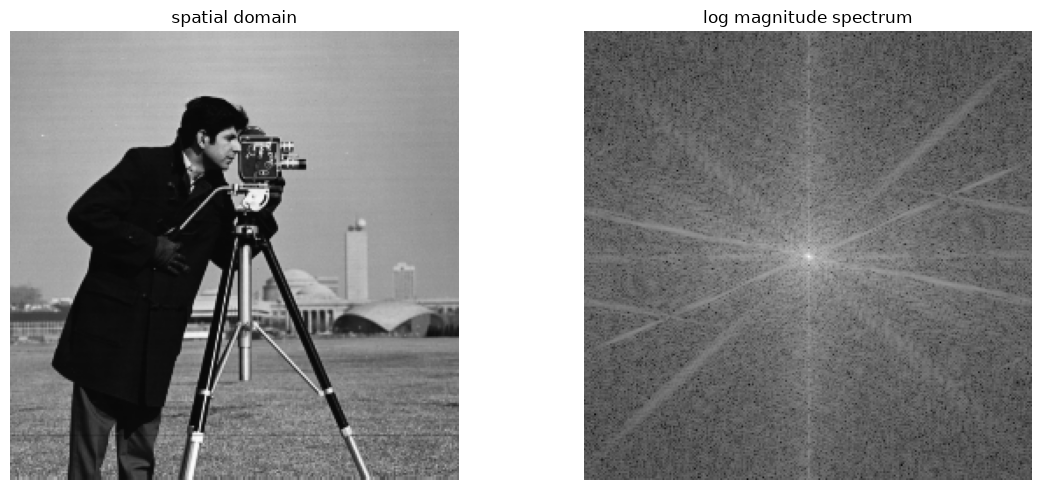

In [43]:
fourier_input = cv.imread("testimgs/cameraman.tif", cv.IMREAD_GRAYSCALE)
if fourier_input is None:
    raise FileNotFoundError("无法读取 testimgs/cameraman.tif")

frequency = np.fft.fft2(fourier_input)
frequency_centered = np.fft.fftshift(frequency)
magnitude = np.abs(frequency_centered)
spectrum = np.log1p(magnitude)

print("空间域：", fourier_input.shape, fourier_input.dtype)
print("频域：", frequency.shape, frequency.dtype)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(fourier_input, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("spatial domain")
axes[1].imshow(spectrum, cmap="gray")
axes[1].set_title("log magnitude spectrum")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

### 练习问题与解答

#### 1. `np.fft.fft2()` 的结果为什么是复数？

因为傅里叶变换同时记录每个频率成分的幅度和相位，复数的实部和虚部共同表示这两类信息。

#### 2. 为什么频谱显示前要使用 `np.abs()`？

频域结果是复数图像，通常使用复数的模表示频率成分强弱，`np.abs()` 可以得到每个频率位置的幅度。

#### 3. 为什么使用 `np.log1p()`？

频谱幅度的动态范围通常很大，直接显示时强亮区域会掩盖其他细节。对幅度取 `log(1 + magnitude)` 可以压缩动态范围；`log1p()` 在输入为 0 时也能安全计算。

#### 4. `np.fft.fftshift()` 的作用是什么？

它把零频率分量从数组角落移动到频谱中心，使低频位于中心、高频位于四周，更符合频谱的直观显示方式。

#### 5. 为什么频域结果仍然保留相位信息？

幅度表示频率成分强弱，但相位包含空间位置信息。只保留幅度而丢弃相位，通常无法正确恢复原图像。